# Implementación de un Mecanismo de Atención para Series de Tiempo

## Descripción

Este notebook desarrolla la implementación de un mecanismo de atención aplicado al análisis y predicción de series de tiempo mediante técnicas de Deep Learning.

El objetivo es comprender cómo los mecanismos de atención permiten identificar y asignar diferentes niveles de importancia a los valores anteriores de una secuencia temporal para realizar predicciones.

## Objetivos

- Comprender el funcionamiento de los mecanismos de atención.
- Preparar y procesar datos temporales.
- Implementar un mecanismo de atención utilizando TensorFlow y Keras.
- Entrenar un modelo de predicción.
- Evaluar su rendimiento mediante métricas de error.
- Visualizar los resultados y analizar los pesos de atención.

## Tecnologías

Python, TensorFlow, Keras, NumPy, Pandas, Matplotlib y Scikit-learn.

In [1]:
# Importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("TensorFlow:", tf.__version__)
print("Librerías importadas correctamente.")

TensorFlow: 2.21.0
Librerías importadas correctamente.


## 1. Generación de datos

En esta sección se genera una serie de tiempo sintética que representa una variable que cambia a lo largo de diferentes periodos.

Los datos contienen una tendencia, componentes periódicos y ruido aleatorio. Esta combinación permite simular comportamientos temporales y evaluar la capacidad del modelo para identificar patrones.

In [2]:
# Generación de datos sintéticos

np.random.seed(42)

tiempo = np.arange(1500)

tendencia = 0.005 * tiempo

estacionalidad = (
    0.8 * np.sin(2 * np.pi * tiempo / 50) +
    0.4 * np.sin(2 * np.pi * tiempo / 20)
)

ruido = np.random.normal(0, 0.15, 1500)

serie = tendencia + estacionalidad + ruido

datos = pd.DataFrame({
    "Tiempo": tiempo,
    "Valor": serie
})

print(datos.head())
print("\nCantidad de registros:", len(datos))

   Tiempo     Valor
0       0  0.074507
1       1  0.208134
2       2  0.541219
3       3  0.861561
4       4  0.750703

Cantidad de registros: 1500


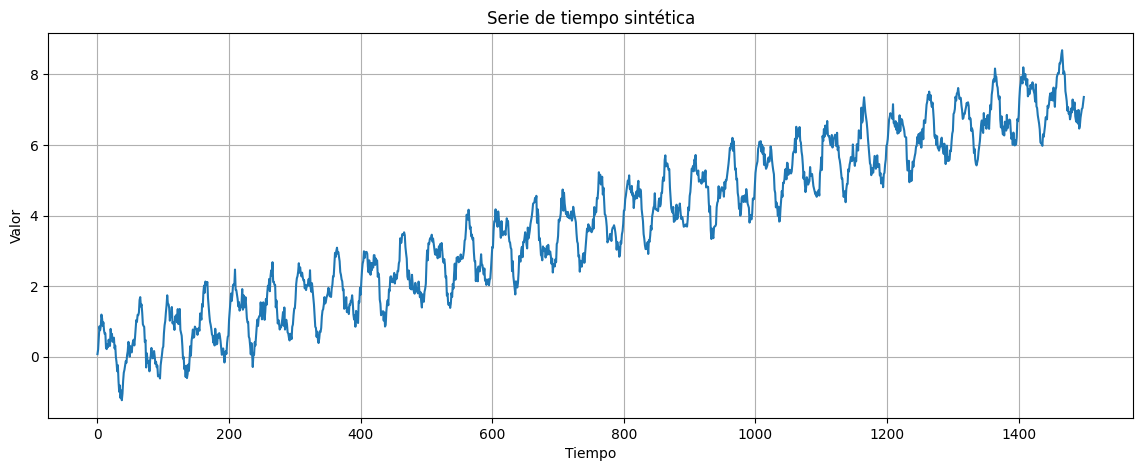

In [3]:
# Visualización de la serie temporal

plt.figure(figsize=(14, 5))

plt.plot(datos["Tiempo"], datos["Valor"])

plt.title("Serie de tiempo sintética")
plt.xlabel("Tiempo")
plt.ylabel("Valor")
plt.grid(True)

plt.show()

## 2. Preparación de los datos

Los datos se dividen cronológicamente en conjuntos de entrenamiento y prueba. Posteriormente, se aplica una normalización mediante MinMaxScaler para transformar los valores a un intervalo entre 0 y 1.

La normalización facilita el entrenamiento de la red neuronal y evita que las diferencias de escala afecten su aprendizaje.

In [4]:
# División cronológica de los datos

valores = datos["Valor"].values.reshape(-1, 1)

limite = int(len(valores) * 0.80)

train_data = valores[:limite]
test_data = valores[limite:]

# Normalización utilizando únicamente entrenamiento

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

print("Datos de entrenamiento:", len(train_scaled))
print("Datos de prueba:", len(test_scaled))

Datos de entrenamiento: 1200
Datos de prueba: 300


## 3. Construcción de secuencias

Se utiliza una ventana temporal de 30 valores anteriores para predecir el siguiente valor de la serie.

Este procedimiento transforma los datos originales en pares de entrada y salida que pueden ser utilizados por el modelo de aprendizaje profundo.

In [5]:
# Función para crear ventanas temporales

def crear_secuencias(data, ventana=30):

    X, y = [], []

    for i in range(len(data) - ventana):
        X.append(data[i:i + ventana])
        y.append(data[i + ventana])

    return np.array(X), np.array(y)


# Crear secuencias de entrenamiento

X_train, y_train = crear_secuencias(train_scaled)

# Crear secuencias de prueba
# Se incluyen los últimos 30 valores del entrenamiento
# para obtener el contexto inicial de prueba.

test_completo = np.concatenate(
    [train_scaled[-30:], test_scaled],
    axis=0
)

X_test, y_test = crear_secuencias(test_completo)

print("Forma de X_train:", X_train.shape)
print("Forma de y_train:", y_train.shape)

print("Forma de X_test:", X_test.shape)
print("Forma de y_test:", y_test.shape)

Forma de X_train: (1170, 30, 1)
Forma de y_train: (1170, 1)
Forma de X_test: (300, 30, 1)
Forma de y_test: (300, 1)


## 4. Implementación del mecanismo de atención

Se desarrolla una capa personalizada de atención utilizando TensorFlow y Keras.

El mecanismo calcula puntuaciones para cada elemento de la secuencia temporal y aplica la función Softmax para obtener pesos de atención.

Posteriormente, los pesos se utilizan para realizar una combinación ponderada de los valores de la secuencia. De esta manera, el modelo puede asignar mayor importancia a determinados pasos temporales durante el proceso de predicción.

In [6]:
# Capa personalizada de atención

class AttentionPooling(tf.keras.layers.Layer):

    def __init__(self, units=32):
        super().__init__()

        self.dense1 = tf.keras.layers.Dense(
            units,
            activation="tanh"
        )

        self.dense2 = tf.keras.layers.Dense(1)

    def call(self, inputs):

        # Calcular puntuaciones de atención

        scores = self.dense2(
            self.dense1(inputs)
        )

        # Obtener pesos mediante Softmax

        weights = tf.nn.softmax(
            scores,
            axis=1
        )

        # Suma ponderada de la secuencia

        context = tf.reduce_sum(
            inputs * weights,
            axis=1
        )

        return context, weights

## 5. Construcción del modelo de atención

Se construye una red neuronal que recibe secuencias temporales de 30 valores. Posteriormente, la capa de atención calcula la importancia de cada posición y genera un vector de contexto que se utiliza para producir la predicción.

La capa final utiliza una neurona con activación lineal para estimar el siguiente valor de la serie de tiempo.

In [7]:
# Construcción del modelo

entrada = tf.keras.Input(shape=(30, 1))

atencion = AttentionPooling(units=32)

contexto, pesos = atencion(entrada)

salida = tf.keras.layers.Dense(1)(contexto)

modelo_atencion = tf.keras.Model(
    inputs=entrada,
    outputs=salida
)

# Compilación

modelo_atencion.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Resumen del modelo

modelo_atencion.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_pooling               │ [(None, 1), (None, 30, │            97 │
│ (AttentionPooling)              │ 1)]                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99 (396.00 B)

 Trainable params: 99 (396.00 B)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento del modelo

El modelo se entrena utilizando el optimizador Adam y la función de pérdida Mean Squared Error (MSE).

Se establecen 30 épocas de entrenamiento y un tamaño de lote de 32 muestras. Durante el entrenamiento se utiliza el conjunto de prueba como validación para observar el comportamiento del error en datos no utilizados para actualizar los pesos.

In [8]:
# Entrenamiento

historial_atencion = modelo_atencion.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0097 - mae: 0.0839 - val_loss: 0.0090 - val_mae: 0.0802
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0093 - mae: 0.0834 - val_loss: 0.0088 - val_mae: 0.0797
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - mae: 0.0829 - val_loss: 0.0086 - val_mae: 0.0792
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - mae: 0.0826 - val_loss: 0.0085 - val_mae: 0.0789
Epoch 5/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0090 - mae: 0.0823 - val_loss: 0.0083 - val_mae: 0.0787
Epoch 6/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0089 - mae: 0.0819 - val_loss: 0.0083 - val_mae: 0.0785
Epoch 7/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0089 - mae: 0.0816 - val_loss: 0.0082 - val_mae: 0.0784
Epoch 8/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0088 - mae: 0.0814 - val_loss: 0.0082 - val_mae: 0.0785
Epoch 9/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0088 - mae:

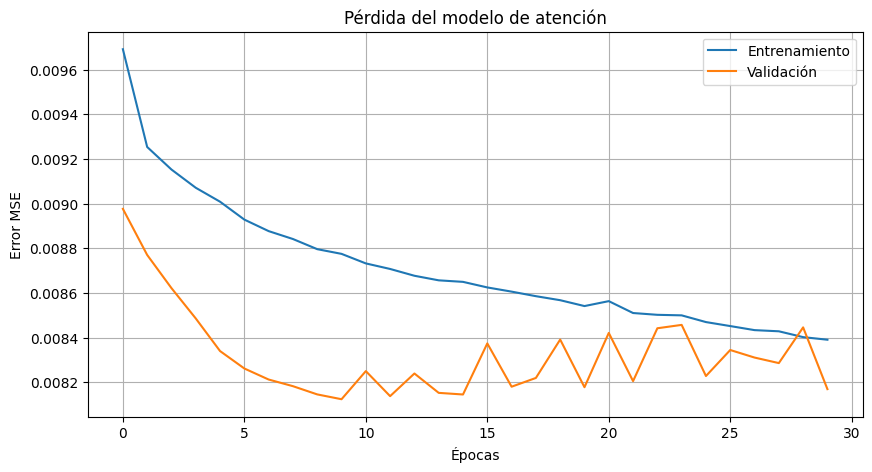

In [9]:
# Gráfica de pérdida durante el entrenamiento

plt.figure(figsize=(10, 5))

plt.plot(
    historial_atencion.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    historial_atencion.history["val_loss"],
    label="Validación"
)

plt.title("Pérdida del modelo de atención")
plt.xlabel("Épocas")
plt.ylabel("Error MSE")

plt.legend()
plt.grid(True)

plt.show()

## 7. Evaluación del modelo

Se evalúa el rendimiento del mecanismo de atención utilizando datos de prueba.

Para medir la calidad de las predicciones se utilizan las métricas Mean Absolute Error (MAE) y Root Mean Squared Error (RMSE).

Estas métricas permiten cuantificar la diferencia entre los valores reales y los valores estimados por el modelo.

In [10]:
# Realizar predicciones

predicciones = modelo_atencion.predict(X_test)

# Regresar los valores a su escala original

predicciones_reales = scaler.inverse_transform(
    predicciones
)

valores_reales = scaler.inverse_transform(
    y_test
)

# Calcular métricas

mae = mean_absolute_error(
    valores_reales,
    predicciones_reales
)

rmse = np.sqrt(
    mean_squared_error(
        valores_reales,
        predicciones_reales
    )
)

print("Resultados del modelo de atención")
print("---------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Resultados del modelo de atención
---------------------------------
MAE: 0.665713353257403
RMSE: 0.7757696890084659


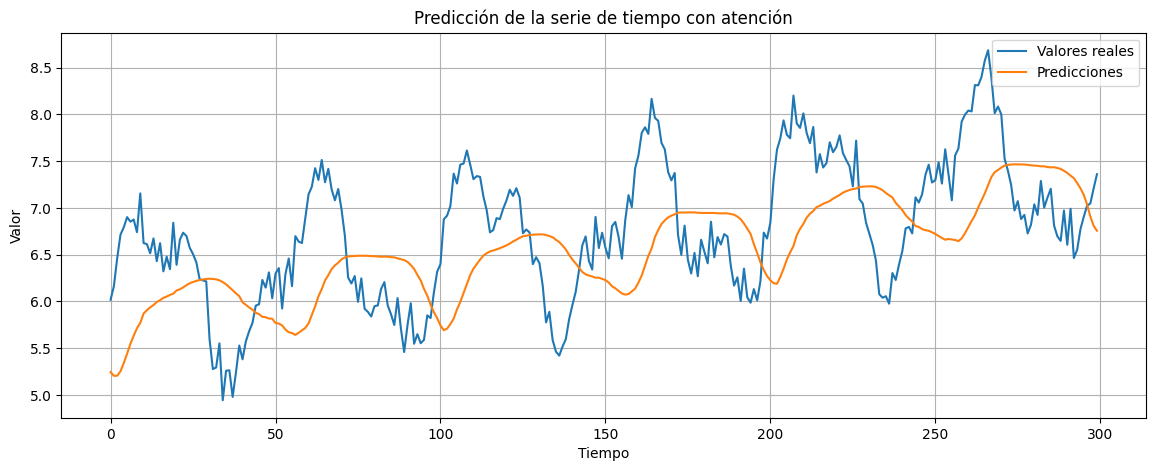

In [11]:
# Visualización de predicciones

plt.figure(figsize=(14, 5))

plt.plot(
    valores_reales,
    label="Valores reales"
)

plt.plot(
    predicciones_reales,
    label="Predicciones"
)

plt.title("Predicción de la serie de tiempo con atención")
plt.xlabel("Tiempo")
plt.ylabel("Valor")

plt.legend()
plt.grid(True)

plt.show()

## 8. Visualización de los pesos de atención

Se extraen los pesos generados por el mecanismo de atención para observar cómo se distribuye la importancia entre los diferentes pasos temporales de entrada.

Esta visualización permite interpretar qué posiciones de la secuencia reciben mayor atención durante el proceso de predicción.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step


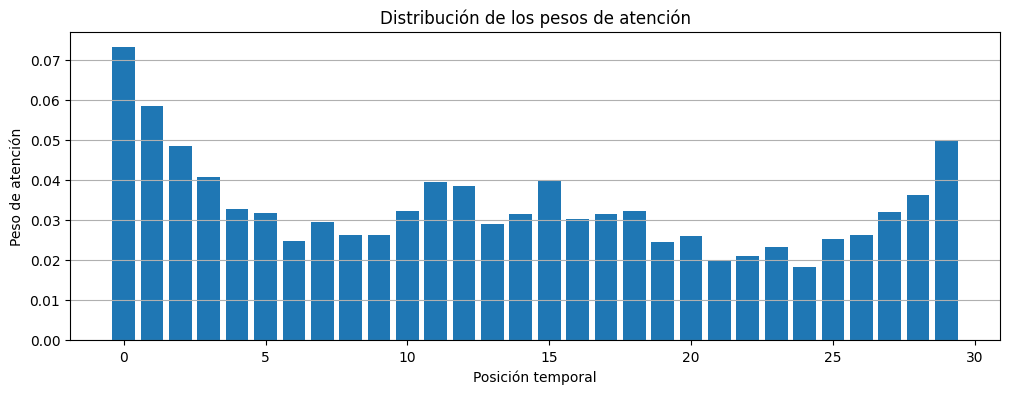

Suma de los pesos: 0.99999994


In [12]:
# Crear un modelo auxiliar para extraer la atención

modelo_pesos = tf.keras.Model(
    inputs=entrada,
    outputs=pesos
)

# Obtener pesos de una muestra de prueba

pesos_atencion = modelo_pesos.predict(
    X_test[:1]
)

# Visualizar pesos

plt.figure(figsize=(12, 4))

plt.bar(
    range(30),
    pesos_atencion[0, :, 0]
)

plt.title("Distribución de los pesos de atención")
plt.xlabel("Posición temporal")
plt.ylabel("Peso de atención")

plt.grid(axis="y")

plt.show()

print("Suma de los pesos:",
      np.sum(pesos_atencion[0]))

## 9. Conclusiones

Mediante esta implementación se desarrolló un mecanismo de atención aplicado a la predicción de series de tiempo utilizando TensorFlow y Keras.

El modelo permitió identificar la importancia relativa de los diferentes valores de entrada mediante la asignación de pesos de atención. Posteriormente, estos pesos fueron utilizados para construir un vector de contexto que facilitó la predicción del siguiente valor de la secuencia.

Los resultados obtenidos mediante las métricas MAE y RMSE permitieron evaluar el comportamiento del modelo sobre datos de prueba. Asimismo, la visualización de los pesos de atención facilitó la comprensión del funcionamiento interno del mecanismo.

Esta práctica permitió reconocer la utilidad de la atención para seleccionar información relevante dentro de secuencias temporales.